# 잘못 나온 케이스 모음

In [2]:
%load_ext autoreload
%autoreload 2

import os
import random
import sys
sys.path.append("/home/dev/pose_v2")

from pose.config import get_cfg_defaults

%matplotlib inline
import math
import torch

from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import InterpolationMode
from torchvision.transforms.v2 import ToPILImage
from torchvision.transforms.v2.functional import affine

from torchvision.utils import draw_bounding_boxes
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

cfg = get_cfg_defaults()

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

In [3]:
from pose.data.dataset import CocoDataset

pose_dataset = CocoDataset(cfg, is_train=True, transform=None)
pose_dataset.do_data_augment = False

2025-02-01 21:47:31.811 | INFO     | pose.data.dataset:_init_coco_info:143 - Keypoints idx2name: dict_items([(0, 'nose'), (1, 'L-eye'), (2, 'R-eye'), (3, 'L-ear'), (4, 'R-ear'), (5, 'L-shder'), (6, 'R-shder'), (7, 'L-elb'), (8, 'R-elb'), (9, 'L-wrst'), (10, 'R-wrst'), (11, 'L-hip'), (12, 'R-hip'), (13, 'L-knee'), (14, 'R-knee'), (15, 'L-ankl'), (16, 'R-ankl')])
2025-02-01 21:47:33.820 | INFO     | pose.data.dataset:__init__:54 - Annotation fname: /home/dev/data/coco/annotations/person_keypoints_train2017.json
2025-02-01 21:47:33.820 | INFO     | pose.data.dataset:__init__:56 - Image file directory: /home/dev/data/coco/images/train2017/
2025-02-01 21:47:33.820 | INFO     | pose.data.dataset:__init__:59 - NN input size(height, width): [256, 192]
2025-02-01 21:47:33.821 | INFO     | pose.data.dataset:__init__:82 - Data augmentation: True
2025-02-01 21:47:33.898 | INFO     | pose.data.dataset:__init__:90 - Num images: 118,287
2025-02-01 21:47:33.898 | INFO     | pose.data.dataset:__init__:

In [4]:
import cv2
import numpy as np
from torchvision import transforms
from pose.hrnet.dataset import HRNetCocoDataset

hrnet_dataset = HRNetCocoDataset(cfg, is_train=True, transform=None)

hrnet_annoid2idx = {}
for idx, data in enumerate(hrnet_dataset.db):
    hrnet_annoid2idx[data['anno_id']] = idx

loading annotations into memory...


2025-02-01 21:47:53.859 | INFO     | pose.hrnet.dataset:__init__:93 - => classes: ['__background__', 'person']
2025-02-01 21:47:53.860 | INFO     | pose.hrnet.dataset:__init__:108 - => num_images: 118287


Done (t=2.18s)
creating index...
index created!


2025-02-01 21:47:59.017 | INFO     | pose.hrnet.dataset:__init__:118 - => load 149813 samples


In [5]:
skeleton = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
            [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
            [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

def get_connected_keypoints(keypoint_idx: int) -> list[int]:
    ret = set()
    for a, b in skeleton:
        if a == keypoint_idx:
            ret.add(b)
        elif b == keypoint_idx:
            ret.add(a)
    return list(ret)

In [6]:
def draw_hrnet_data(anno_id, verbose=False):
    hrnet_idx = hrnet_annoid2idx[anno_id]
    if verbose:
        print(f"hrnet index: {hrnet_idx}")
    
    nn_input, target_y, target_x, target_weight, extra_info = hrnet_dataset[hrnet_idx]
    nn_input = cv2.cvtColor(nn_input, cv2.COLOR_BGR2RGB)
    
    _image_id = int(extra_info['image'].split('/')[-1].split('.')[0])
    if verbose:
        print(f"image id: {_image_id}")
    
    kp = extra_info['joints'][:, 0:2]
    vis = extra_info['joints_vis'][:, 0]
    
    img = nn_input
    for i in range(17):
        x, y = kp[i]
        _vis = vis[i]
        if _vis == 1:
            c = COLOR_YELLOW
        else: # vis == 0
            continue
        img = cv2.circle(img, (int(x), int(y)), 2, c, 2)
        connected_keypoints = get_connected_keypoints(i)
        for conn in connected_keypoints:
            if vis[conn] != 0:
                dst = (int(kp[conn][0]), int(kp[conn][1]))
                img = cv2.line(img, (int(x), int(y)), dst, COLOR_MAGENTA, 2)
    
    plt.imshow(img)
    plt.show()

In [7]:
from loguru import logger
logger.remove()
logger.add(sys.stderr, level="INFO")

1

In [8]:
def draw_image(meta, verbose=False):
    image_id = meta['image_id']
    y, x, h, w = meta['bbox']
    bbox = np.array([x, y, w, h])
    image_path = f"/home/dev/data/coco/images/train2017/{str(int(image_id)).zfill(12)}.jpg"
    if verbose:
        print(image_path)
        print(bbox)
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    img_rec = cv2.rectangle(img, bbox, COLOR_MAGENTA, 3)
    plt.imshow(img_rec)
    plt.show()

In [9]:
def check(idx=None, verbose=False):
    if idx is None:
        idx = random.randint(0, len(pose_dataset)-1)
    
    nn_input, target_y, target_x, target_weight, extra_info = pose_dataset[idx]
    
    print("\n### original image ###")
    draw_image(extra_info)
    
    kp = extra_info["keypoints"]
    if verbose:
        print(f"Num keypoints: {int(target_weight.sum())}")
        print(f"nn input size: {nn_input.shape}")
        print(f"nn input: {nn_input}")
        print(f"image id: {extra_info['image_id']}")
        print(f"anno id: {extra_info['anno_id']}")
    
    xy_kp = torch.Tensor(17,2)
    xy_kp[:,0] = kp[:,1]
    xy_kp[:,1] = kp[:,0]
    xy_kp = xy_kp.reshape(1,17,2)
    vis = target_weight.reshape(1,17)
    
    if verbose:
        print(f"joint: {xy_kp}")
        print(f"vis: {vis}")
    
    print("\n### pose.dataset ###")
    nn_input = draw_keypoints(nn_input, xy_kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
    nn_input = to_pil(nn_input)
    plt.imshow(nn_input)
    plt.show()
    
    anno_id = extra_info['anno_id']
    
    print("\n### hrnet.dataset ###")
    draw_hrnet_data(int(anno_id))

    print(f"\npose.dataset.idx(anno_id): {idx}({anno_id})")

# 잘못 나온 케이스들


### original image ###


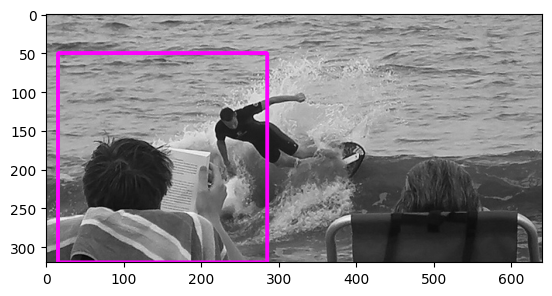


### pose.dataset ###


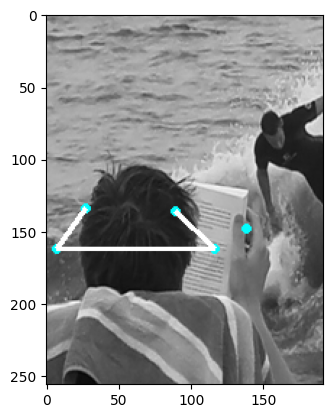


### hrnet.dataset ###


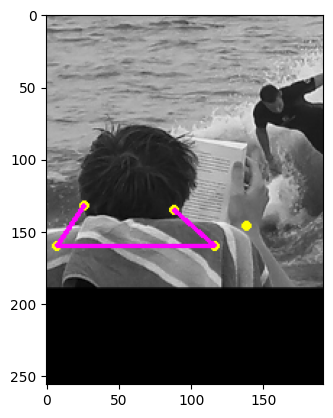


pose.dataset.idx(anno_id): 68724(445400)


In [10]:
check(idx=68724)


### original image ###


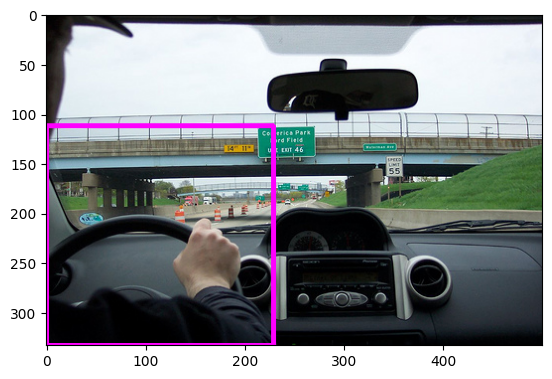


### pose.dataset ###


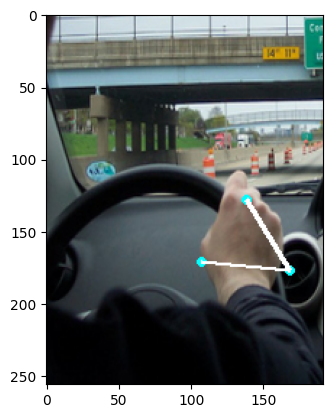


### hrnet.dataset ###


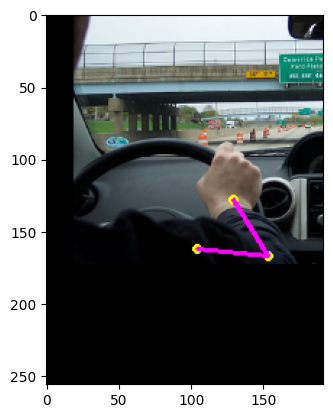


pose.dataset.idx(anno_id): 9755(2206265)


In [11]:
check(idx=9755)


### original image ###


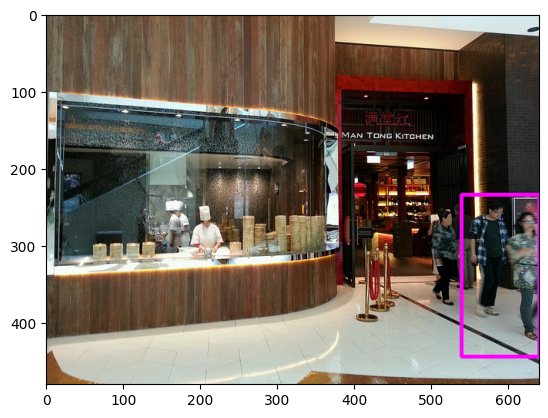


### pose.dataset ###


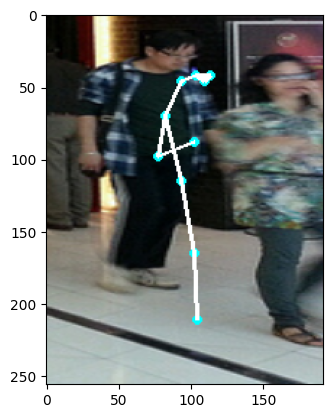


### hrnet.dataset ###


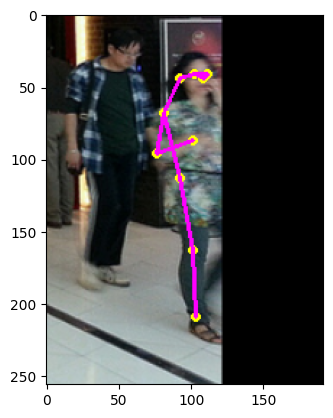


pose.dataset.idx(anno_id): 118688(1294045)


In [12]:
check(idx=118688)


### original image ###


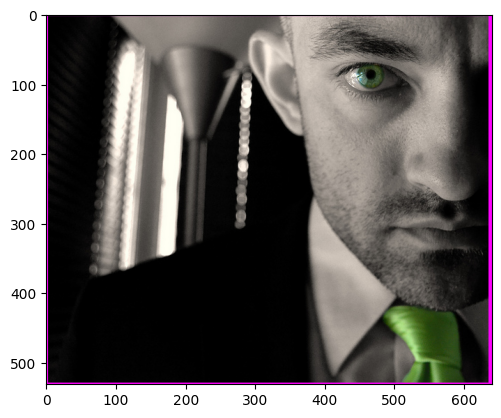


### pose.dataset ###


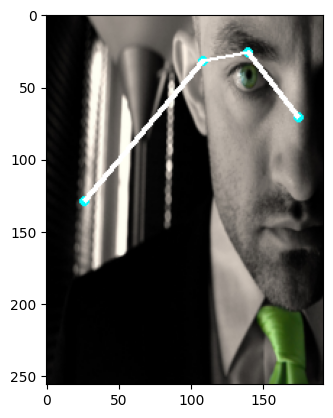


### hrnet.dataset ###


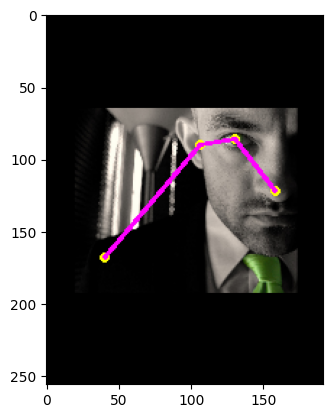


pose.dataset.idx(anno_id): 13605(1272894)


In [13]:
check(idx=13605)


### original image ###


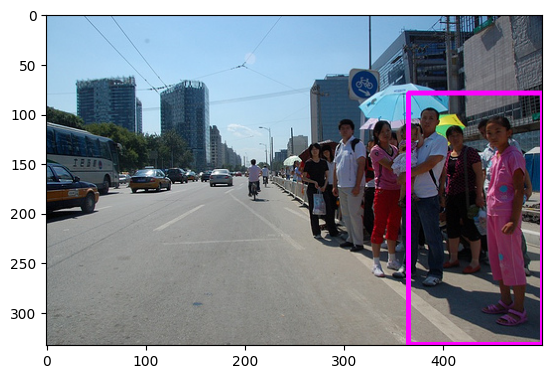


### pose.dataset ###


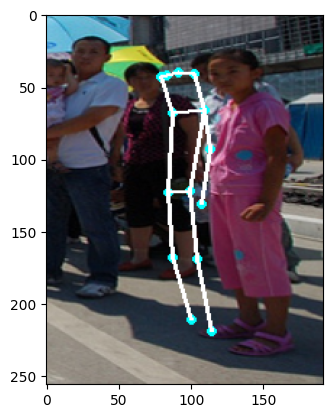


### hrnet.dataset ###


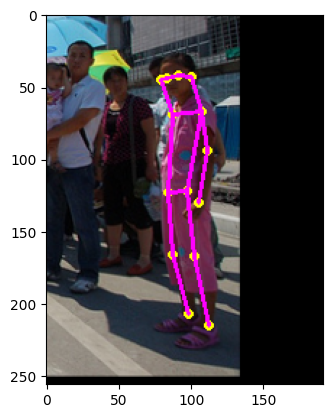


pose.dataset.idx(anno_id): 4634(240337)


In [14]:
check(idx=4634)


### original image ###


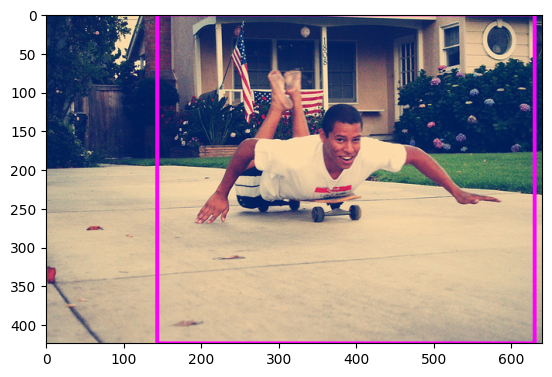


### pose.dataset ###


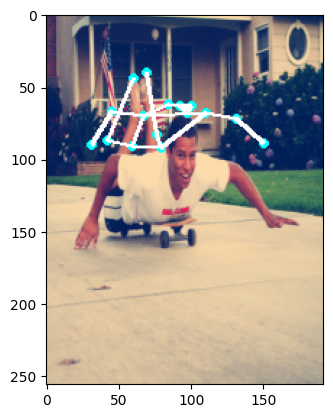


### hrnet.dataset ###


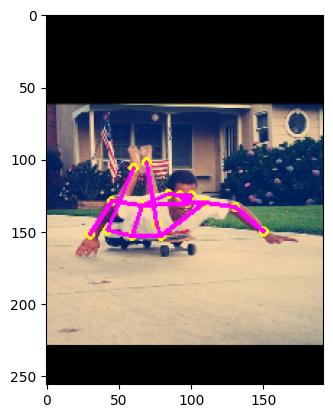


pose.dataset.idx(anno_id): 84528(493107)


In [15]:
check(idx=84528)


### original image ###


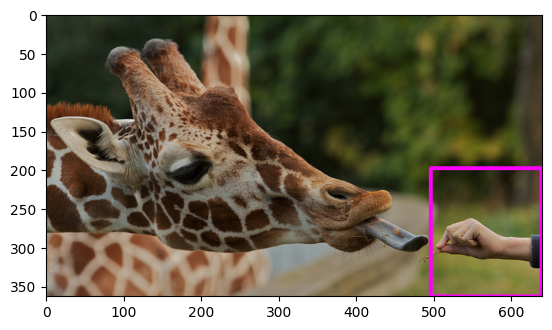


### pose.dataset ###


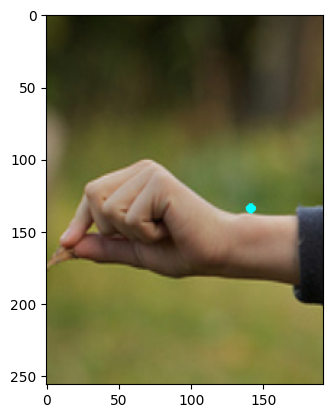


### hrnet.dataset ###


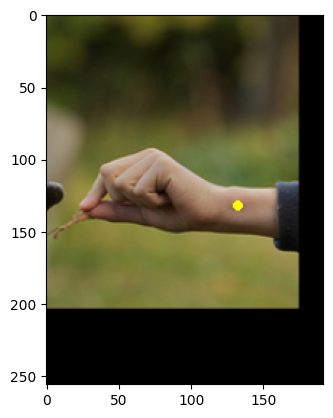


pose.dataset.idx(anno_id): 148167(2166449)


In [17]:
check(idx=148167)


### original image ###


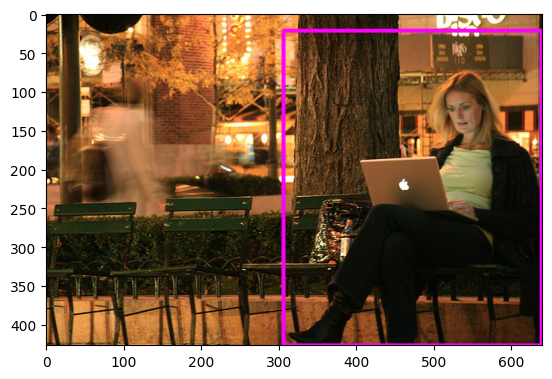


### pose.dataset ###


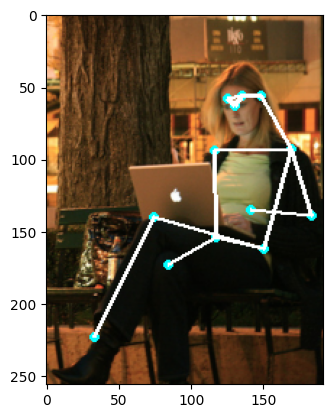


### hrnet.dataset ###


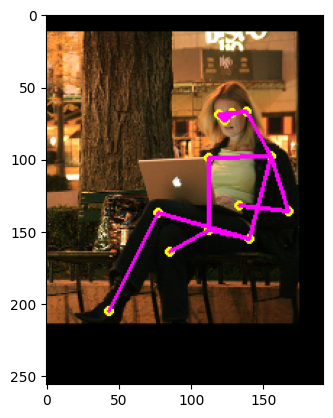


pose.dataset.idx(anno_id): 34493(204361)


In [19]:
check(idx=34493)


### original image ###


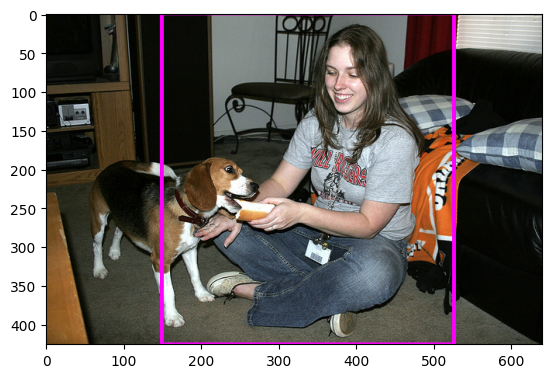


### pose.dataset ###


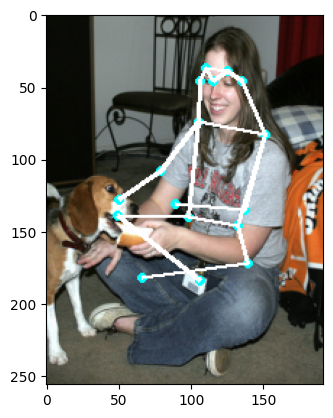


### hrnet.dataset ###


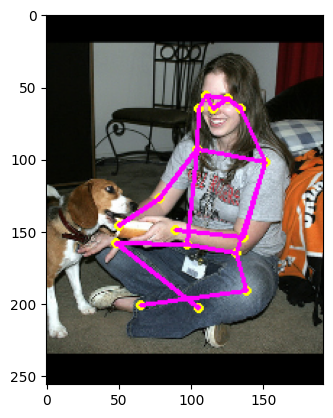


pose.dataset.idx(anno_id): 44952(186634)


In [26]:
check(idx=44952)


### original image ###


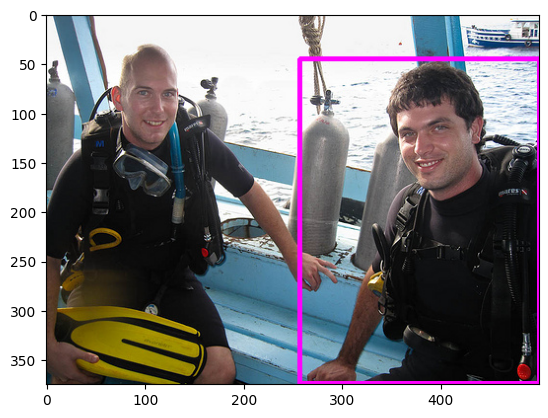


### pose.dataset ###


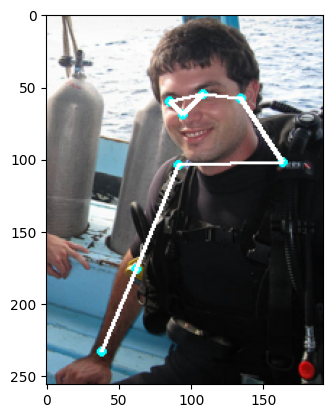


### hrnet.dataset ###


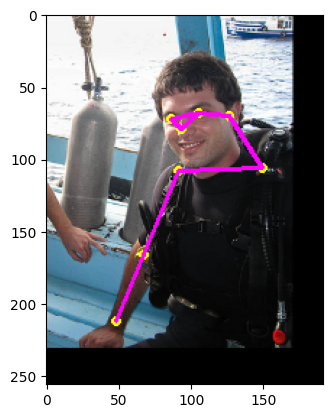


pose.dataset.idx(anno_id): 52576(211790)


In [28]:
# 에러 케이스는 아님. 참고 목적으로, 앞서 테스트 했던걸 확인해봤음.
check(idx=52576)